# Nombre: Pablo Alejandro Mafla Ayala
# Tarea 3.2 - Exploración de datos (EDA)

--- ESTRUCTURA DEL DATASET ---
<class 'pandas.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt               310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    str    
dtypes: float64(6), str(1)
memory usage: 17.1 KB

--- ESTADÍSTICAS DESCRIPTIVAS ---


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
count,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,60.496653,17.542822,51.930930,42.953831,117.920655,26.296694
std,17.236520,10.008330,18.554064,13.423102,13.317377,37.559027
min,26.147921,-6.554948,14.000000,13.366931,70.082575,-11.058179
25%,46.430294,10.667069,37.000000,33.347122,110.709196,1.603727
50%,58.691038,16.357689,49.562398,42.404912,118.268178,11.767934
75%,72.877696,22.120395,63.000000,52.695888,125.467674,41.287352
max,129.834041,49.431864,125.742385,121.429566,163.071041,418.543082



--- MATRIZ DE CORRELACIÓN ---


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
pelvic_incidence,1.000000,0.629199,0.717282,0.814960,-0.247467,0.638743
pelvic_tilt,0.629199,1.000000,0.432764,0.062345,0.032668,0.397862
lumbar_lordosis_angle,0.717282,0.432764,1.000000,0.598387,-0.080344,0.533667
sacral_slope,0.814960,0.062345,0.598387,1.000000,-0.342128,0.523557
pelvic_radius,-0.247467,0.032668,-0.080344,-0.342128,1.000000,-0.026065
degree_spondylolisthesis,0.638743,0.397862,0.533667,0.523557,-0.026065,1.000000


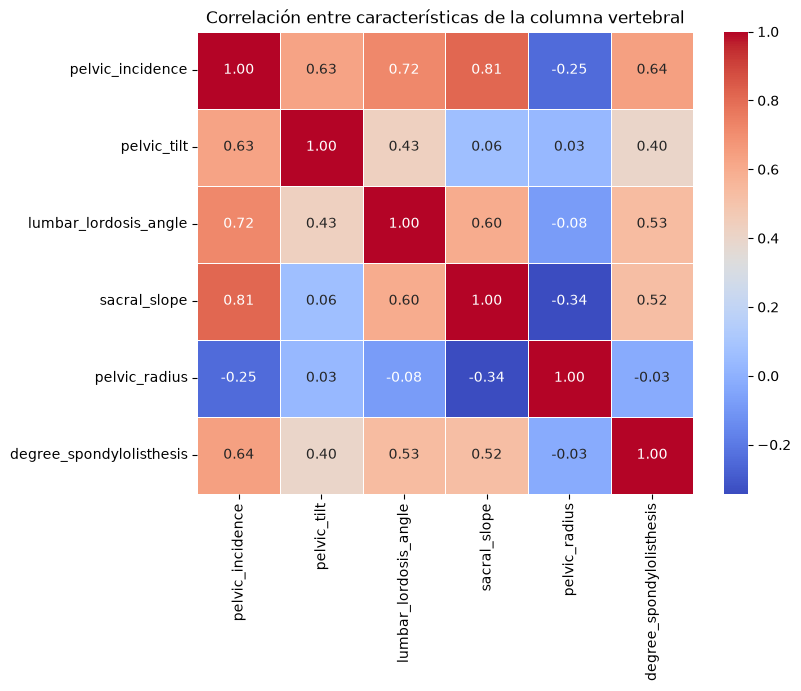

In [1]:
import pandas as pd
from scipy.io import arff
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar los datos
data = arff.loadarff('column_2C_weka.arff')
df = pd.DataFrame(data[0])

# La columna 'class' viene en formato de bytes (ej. b'Abnormal'). La convertimos a texto normal:
df['class'] = df['class'].str.decode('utf-8')

# 2. Explorar la estructura del dataset
print("--- ESTRUCTURA DEL DATASET ---")
df.info()

# 3. Mostrar estadísticas descriptivas (Media, desviación estándar, mínimos y máximos)
print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())

# 4. Buscar correlación entre las características numéricas
print("\n--- MATRIZ DE CORRELACIÓN ---")
numeric_df = df.drop('class', axis=1) # Separamos el texto para poder hacer matemáticas
correlacion = numeric_df.corr()
display(correlacion)

# 5. Visualizar la correlación con un gráfico
plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlación entre características de la columna vertebral')
plt.show()